# WP03 son kontrol eki

Bu ek, orijinal WP03 notebook'unu değiştirmeden 62/36 ilaç tablolarını ve etiket stratejisi ölçümlerini gösterir. Büyük kaynaklar okunmaz. Tablolar `wp03_final_review.py` tarafından mevcut QA dosyalarından bağımsız hesaplanmıştır. Nihai 30 kategori, model girdisi ve öğrenme ayrımı oluşturulmaz.

In [1]:
from pathlib import Path
import json,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_rows',100)
pd.set_option('display.max_colwidth',180)
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'AGENTS.md').exists())
QA=ROOT/'reports/qa/WP03/final_review';FIG=ROOT/'reports/figures/WP03/final_review';FIG.mkdir(parents=True,exist_ok=True)
def read(n):return pd.read_csv(QA/n,keep_default_na=False)
checks=json.loads((QA/'consistency_checks.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'kontrol':x['check'],'sonuç':'GEÇTİ' if x['passed'] else 'KALDI'} for x in checks]))
assert all(x['passed'] for x in checks)

,kontrol,sonuç
0,unique_mapping_ID,GEÇTİ
1,mapping_candidates,GEÇTİ
2,cid_count,GEÇTİ
3,exact_count,GEÇTİ
4,positive_id_set_equals_exact_set,GEÇTİ
5,has_pt_flag_equals_positive_set,GEÇTİ
6,unique_positive_key_duplicates,GEÇTİ
7,conservative_positive_rows,GEÇTİ
8,per_drug_PT_counts_mismatch,GEÇTİ
9,old38_flags_independent,GEÇTİ


## Kesin eşleşen 62 ilaç

PT sayısı benzersiz CUI sayısıdır. Mevcut kimya, eski beş özellik kaydının bulunmasıdır; yeni molekül grafı hazır demek değildir. Protein bayrağı WP02 XML kimlik kontrolünden gelir. V6 üyeliği eski 38 ID listesiyle karşılaştırılmıştır. Bu sütunlar QA içindir; model girdisi olarak dışa aktarılmaz.

In [2]:
display(read('accepted_62.csv'))

,DrugBank ID,İlaç,Benzersiz PT,Mevcut kimya,XML protein kimliği,Eski V6 38 üyeliği
0,DB00479,Amikacin,27,Yok,Var,Yok
1,DB01060,Amoxicillin,79,Var,Var,Var
2,DB00415,Ampicillin,27,Var,Var,Var
3,DB00207,Azithromycin,177,Var,Var,Yok
4,DB01053,Benzylpenicillin,135,Var,Var,Var
5,DB00578,Carbenicillin,26,Var,Var,Var
6,DB01327,Cefazolin,84,Yok,Var,Yok
7,DB00535,Cefdinir,100,Yok,Var,Yok
8,DB01413,Cefepime,91,Yok,Var,Yok
9,DB00671,Cefixime,49,Yok,Var,Yok


## Eski 38 dışında kalan 36 ilaç

“Yeni” kimlik kazanımı 36'dır. Önceki 38'in yalnız 26'sı aynı muhafazakâr kapsamda kaldığı için 26+36=62; ham 38→62 farkı ile yeni ID sayısı birbirinden ayrılır.

In [3]:
display(read('new_36.csv'))

,DrugBank ID,İlaç,Benzersiz PT,Mevcut kimya,XML protein kimliği,Eski V6 38 üyeliği
0,DB00479,Amikacin,27,Yok,Var,Yok
1,DB00207,Azithromycin,177,Var,Var,Yok
2,DB01327,Cefazolin,84,Yok,Var,Yok
3,DB00535,Cefdinir,100,Yok,Var,Yok
4,DB01413,Cefepime,91,Yok,Var,Yok
5,DB00671,Cefixime,49,Yok,Var,Yok
6,DB00493,Cefotaxime,58,Yok,Var,Yok
7,DB01331,Cefoxitin,62,Yok,Var,Yok
8,DB01416,Cefpodoxime,174,Yok,Var,Yok
9,DB01150,Cefprozil,59,Yok,Var,Yok


## Kategori anlamları

Daralma/genişleme/birleştirme notları terminoloji inceleme bayrağıdır; dış ontolojiyle klinik eşdeğerlik doğrulaması yapılmadı. Genel böbrek işlevi terimine toksik neden yüklemek, Colitis'e antibiyotik bağlamı eklemek ve ayrı CUI'leri birleştirmek ayrıca karar gerektirir.

In [4]:
display(read('category_semantic_review.csv'))

,kategori,kaynak_PT,CUI,pozitif_ilac_62,inceleme,not
0,Alerjik reaksiyon,Hypersensitivity,C0020517,53,yorumlayıcı çeviri,Hypersensitivity ile kategori adının tam kapsam eşitliği veriyle ispatlanmadı.
1,Anemi,Anaemia,C0002871,34,yüzeysel karşılık; klinik onay değil,Bu dosyada açık çok-CUI birleşmesi yok; tam kavramsal eşdeğerlik ayrıca gözden geçirilmeli.
2,Ağız mantarı,Oral candidiasis,C0006849,15,anlam genişletme riski,Kaynak Oral candidiasis; genel mantar adı kaynak özgüllüğünü kaybedebilir.
3,Baş ağrısı,Headache,C0018681,50,yüzeysel karşılık; klinik onay değil,Bu dosyada açık çok-CUI birleşmesi yok; tam kavramsal eşdeğerlik ayrıca gözden geçirilmeli.
4,Baş dönmesi,Dizziness,C0012833,43,yüzeysel karşılık; klinik onay değil,Bu dosyada açık çok-CUI birleşmesi yok; tam kavramsal eşdeğerlik ayrıca gözden geçirilmeli.
5,Bilinç kaybı,Loss of consciousness / Syncope,C0039070 / C0041657,18,birleştirme / ayrıntı kaybı,Loss of consciousness ve Syncope iki ayrı CUI; aynı kategori. Klinik eşdeğerlik onaylanmadı.
6,C.diff ishal,Clostridium difficile colitis / Pseudomembranous colitis,C0238106 / C1257843,45,birleştirme + neden özgüllüğü riski,Clostridium difficile colitis ve Pseudomembranous colitis birleşiyor; ikinci terime C.diff nedeni otomatik yüklenmemeli.
7,Deri döküntüsü,Rash,C0015230,60,yüzeysel karşılık; klinik onay değil,Bu dosyada açık çok-CUI birleşmesi yok; tam kavramsal eşdeğerlik ayrıca gözden geçirilmeli.
8,Hazımsızlık,Dyspepsia,C0013395,35,yüzeysel karşılık; klinik onay değil,Bu dosyada açık çok-CUI birleşmesi yok; tam kavramsal eşdeğerlik ayrıca gözden geçirilmeli.
9,Hırıltı,Wheezing,C0043144,7,yüzeysel karşılık; klinik onay değil,Bu dosyada açık çok-CUI birleşmesi yok; tam kavramsal eşdeğerlik ayrıca gözden geçirilmeli.


## Seyreklik ve sınıf sıklığı

Payda hep aynı 62 ilaçtır. Sınıf sıklığı pozitif kaydı olan ilaç sayısıdır; hasta prevalansı değildir. Tüm kohorttan elde edilen bu keşif sayıları gelecekte test verisine göre sınıf seçmek, ağırlık hesaplamak veya girdi üretmek için kullanılamaz.

,strategy,cohort_drugs,drugs_with_positive,observed_classes,positive_pairs,class_min,class_max,singleton_classes,classes_at_most_2,classes_below_5,classes_above_half,max_min_support_ratio,per_drug_min,per_drug_median,per_drug_max,possible_pairs_observed_vocabulary,unlabeled_pairs_observed_vocabulary
0,PT_CUI,62,62,1061,6416,1,61,406,556,710,33,61.000000,2,79.5,431,65782,59366
1,historical_30,62,61,30,1011,7,61,0,0,0,16,8.714286,0,16.5,28,1860,849
2,code_dictionary_audit,62,61,30,977,7,61,0,0,0,15,8.714286,0,16.0,28,1860,883


,class_id,positive_drugs,cohort_drugs,observed_positive_fraction,unlabeled_drugs
0,C0027497,61,62,0.983871,1
1,C0015230,60,62,0.967742,2
2,C0042963,59,62,0.951613,3
3,C0011603,57,62,0.919355,5
4,C0011991,55,62,0.887097,7
5,C0002792,54,62,0.870968,8
6,C0020517,53,62,0.854839,9
7,C0033774,53,62,0.854839,9
8,C0042109,52,62,0.838710,10
9,C0040034,52,62,0.838710,10


,class_id,positive_drugs,cohort_drugs,observed_positive_fraction,unlabeled_drugs
0,Mide bulantısı,61,62,0.983871,1
1,Deri döküntüsü,60,62,0.967742,2
2,Kusma,59,62,0.951613,3
3,İshal,55,62,0.887097,7
4,Kaşıntı,53,62,0.854839,9
5,Alerjik reaksiyon,53,62,0.854839,9
6,Trombositopeni,52,62,0.838710,10
7,Baş ağrısı,50,62,0.806452,12
8,Karın ağrısı,49,62,0.790323,13
9,C.diff ishal,45,62,0.725806,17


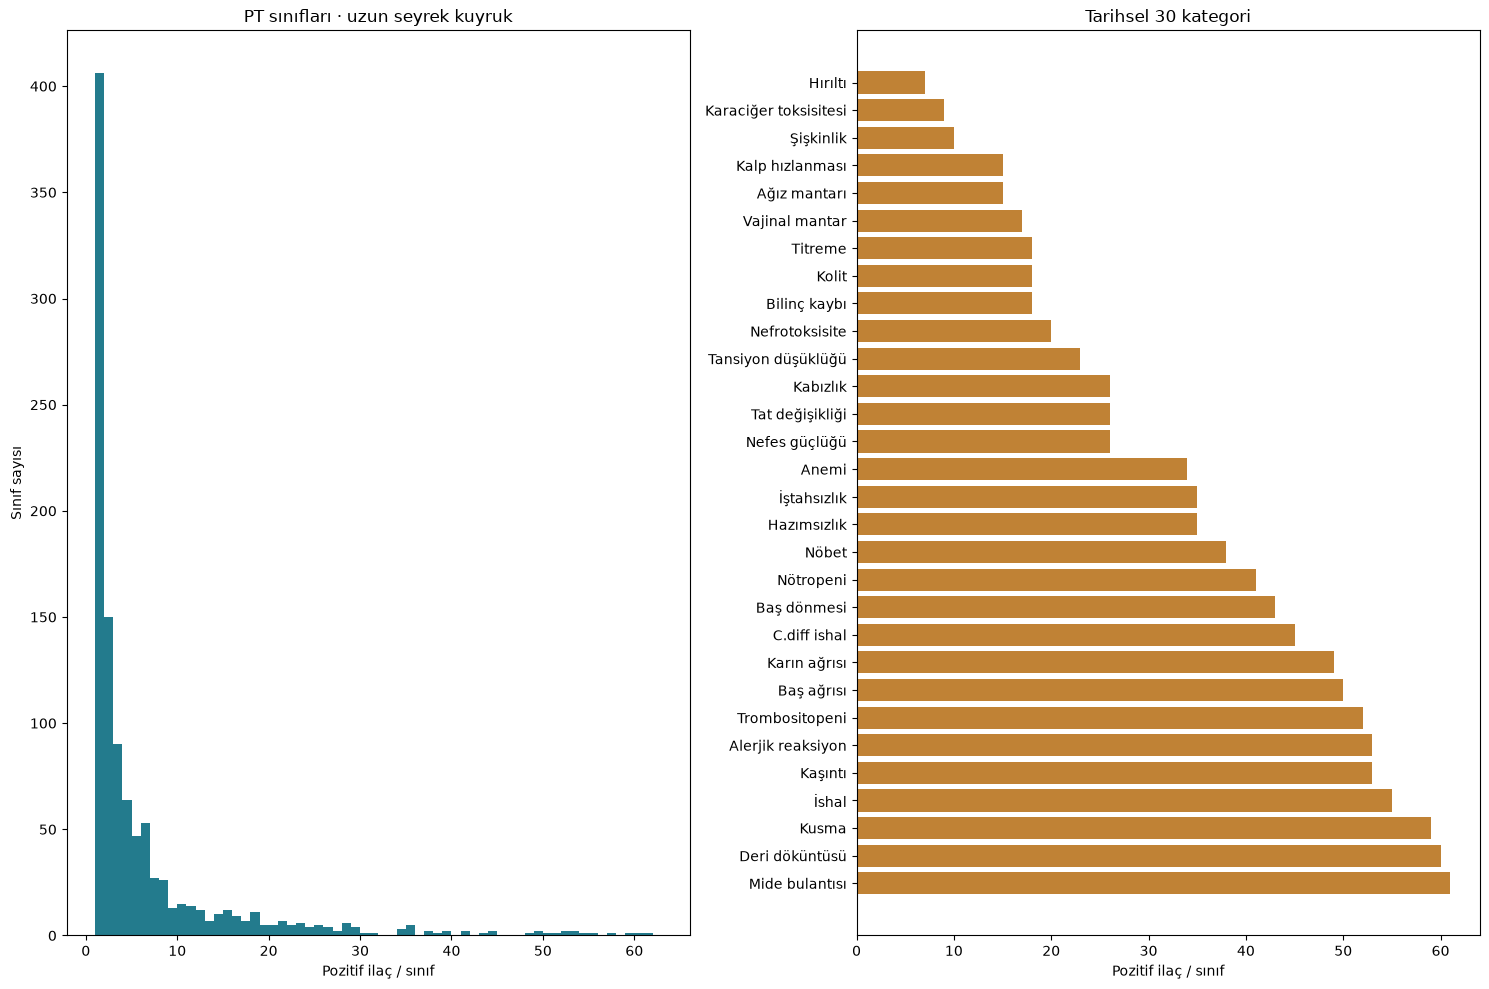

In [5]:
metrics=read('label_strategy_metrics.csv');display(metrics)
pt=read('class_frequency_PT_CUI.csv');cat=read('class_frequency_historical_30.csv')
display(pt.head(15));display(cat)
fig,axes=plt.subplots(1,2,figsize=(12,4));plt.rcParams['font.family']='DejaVu Sans'
axes[0].hist(pt.positive_drugs,bins=range(1,64),color='#237b8d');axes[0].set_title('PT sınıfları · uzun seyrek kuyruk');axes[0].set_xlabel('Pozitif ilaç / sınıf');axes[0].set_ylabel('Sınıf sayısı')
axes[1].barh(cat.class_id,cat.positive_drugs,color='#c08235');axes[1].set_title('Tarihsel 30 kategori');axes[1].set_xlabel('Pozitif ilaç / sınıf')
fig.set_size_inches(15,10);plt.tight_layout();plt.savefig(FIG/'class_support.png',dpi=160);plt.show()

**Yorum:** 1.061 gözlenen PT sınıfının 406'sı tek ilaçta görülüyor. 30 kategoride destek 7–61 arasında; daha yoğun olması kavramsal doğruluğu kanıtlamaz. Seyrek PT'leri sırf sayısal artış için birleştirmek ve eksik kayıtları negatif kabul etmek uygun değildir.

,id,PT_CUI,historical_30,code_dictionary_audit
0,DB00199,56,13,12
1,DB00207,177,23,22
2,DB00254,150,19,19
3,DB00259,2,0,0
4,DB00301,61,18,17
5,DB00303,282,28,27
6,DB00319,102,17,16
7,DB00359,67,11,11
8,DB00415,27,8,7
9,DB00417,19,7,7


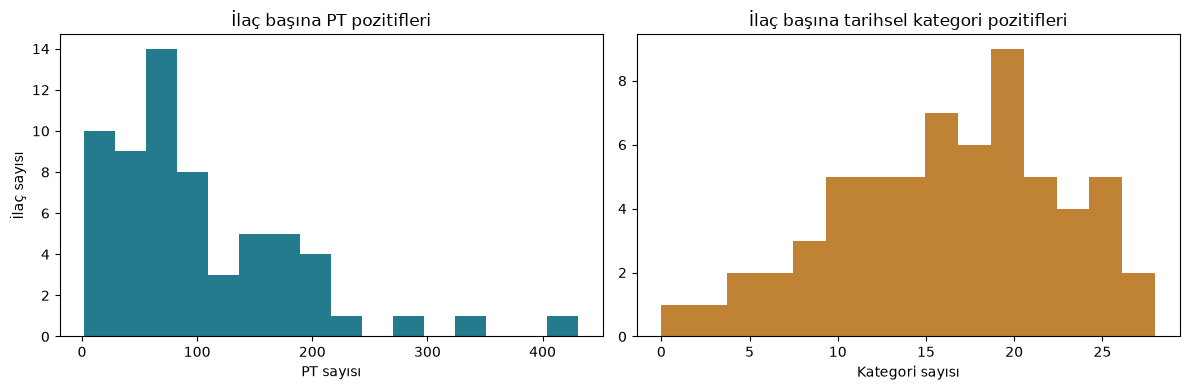

In [6]:
counts=read('per_drug_positive_counts.csv');display(counts)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(counts.PT_CUI,bins=16,color='#237b8d');axes[0].set_title('İlaç başına PT pozitifleri');axes[0].set_xlabel('PT sayısı');axes[0].set_ylabel('İlaç sayısı')
axes[1].hist(counts.historical_30,bins=15,color='#c08235');axes[1].set_title('İlaç başına tarihsel kategori pozitifleri');axes[1].set_xlabel('Kategori sayısı')
plt.tight_layout();plt.savefig(FIG/'per_drug_support.png',dpi=160);plt.show()

**Yorum:** PT sayısındaki farklılık, risk veya etki büyüklüğü olarak yorumlanamaz. Sulfanilamide tarihsel kategorilerde sıfır pozitif taşıyor; bu ilaç için 30 gerçek negatif olduğu anlamına gelmez. Gözlenmeyen çiftler unknown kalır.

## Kapanış kararı

13 eski test geçti; 17 bağımsız tablo tutarlılık kontrolü geçti. Nihai kategori seti değişmedi. Etiket stratejisi kararı ve merkezi ham yol konfigürasyonu önerisi raporda; mevcut çalışan kod yeniden yazılmadı. Statik sızıntı incelemesi gelecekteki eğitim hattı için garanti değildir. WP04 başlamaz; kullanıcı onayı beklenir.